# Reproducibilidad de Resultados: TFM Universidad Europea

**Título:** Autonomía Compartida para UAVs: Desarrollo Sim-to-Real con Webots y RLtools  
**Autora:** Ana Laura Diedrichs  
**Repositorio:** `shared_autonomy_deep_rl`

Este cuaderno interactivo reproduce directamente todas las tablas y figuras cuantitativas de la memoria de TFM (Capítulo 4: *Desarrollo y Resultados*) a partir de los datos experimentales almacenados en `results_TFM/`.

## 1. Configuración del Entorno y Rutas de Datos

In [1]:
import os
import sys
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Añadir raíz del repositorio al path de Python
project_root = os.path.abspath(os.path.join(os.getcwd(), ".."))
if project_root not in sys.path:
    sys.path.insert(0, project_root)

results_dir = os.path.join(project_root, "results_TFM")
output_dir = os.path.join(project_root, "results_TFM")
tables_dir = os.path.join(output_dir, "tables")
figures_dir = os.path.join(output_dir, "figures")
os.makedirs(tables_dir, exist_ok=True)
os.makedirs(figures_dir, exist_ok=True)

print(f"Directorio de datos (lectura) : {results_dir}")
print(f"Directorio de tablas (CSV)    : {tables_dir}")
print(f"Directorio de figuras (PNG)   : {figures_dir}")

Directorio de datos (lectura) : /workspace/results_TFM
Directorio de tablas (CSV)    : /workspace/results_TFM/tables
Directorio de figuras (PNG)   : /workspace/results_TFM/figures


## 2. Tabla 4.1: Configuraciones de Evaluación de Pilotos Degradados
Resumen de los perfiles sintéticos implementados para modelar deficiencias motrices y cognitivas humanas.

In [2]:
from scripts.reproduce_results import get_table_4_1

h41, rows41 = get_table_4_1()
df_4_1 = pd.DataFrame(rows41, columns=h41)
df_4_1

,Perfil,Identificador,Parámetro clave,Mecanismo de falla,Impacto operativo
0,HeuristicPilot (Control P),heuristic_prop,K_p = 2.5 (Directo),Control proporcional cinemático sin horizonte ...,Navegación geométrica nominal determinista de ...
1,NoisyPilot (Moderado),noisy_sigma_0.5,sigma = 0.50,Ruido gaussiano continuo aditivo sobre velocid...,Desviación angular y deriva espacial acumulativa
2,NoisyPilot (Severo),noisy_sigma_1.0,sigma = 1.00,Ruido aditivo de rango dinámico completo,Control errático y trayectorias de choque peri...
3,LaggyPilot (Schaff & Walter),laggy_p_0.8,p_repeat = 0.80,Repetición estocástica del comando previo (ZOH),"Acumulación inercial, sobreoscilación y timeout"
4,StandByPilot (Signal Drop),standby_p_0.8,p_drop = 0.80,Pérdida de paquetes con conmutación reactiva a...,Detención frecuente del avance pero alta integ...


## 3. Tabla 4.2: Comparativa Cuantitativa de Pilotos Óptimos (PPO vs. SAC vs. TD3)
Carga los CSVs empíricos de 100 episodios en `results_TFM/logs/` y compara la cota superior del sistema autónomo.

In [3]:
from scripts.reproduce_results import get_table_4_2

h42, rows42 = get_table_4_2(results_dir)
df_4_2 = pd.DataFrame(rows42, columns=h42)
df_4_2

,Métrica de evaluación,"PPO (SB3, 100 ep)","SAC (RLtools, 100 ep)","TD3 (RLtools, 100 ep)"
0,Tasa de éxito (%),"100.0% [96.3, 100.0]% (100/100)","100.0% [96.3, 100.0]% (100/100)","100.0% [96.3, 100.0]% (100/100)"
1,Recompensa acumulada media,+97.83,+117.17,+117.21
2,Longitud media de episodio,689.00 pasos,303.00 pasos,302.00 pasos
3,Tiempo medio de vuelo,22.05 s,9.70 s,9.66 s
4,Distancia final al objetivo,0.15 m,0.15 m,0.15 m
5,Distancia mín. a obstáculo (láser),0.25 m,0.16 m,0.21 m
6,Altitud final media (m),0.69 m,0.74 m,0.66 m
7,Supervivencia / Integridad,"100.0% [96.3, 100.0]% (100/100)","100.0% [96.3, 100.0]% (100/100)","100.0% [96.3, 100.0]% (100/100)"
8,Artefacto de despliegue,Archivo .zip (PyTorch),Cabecera C++ estática (.h),Cabecera C++ estática (.h)


## 4. Visualización Espacial de Trayectorias (Recinto 2x2m)
Planta $XY$ del recinto de vuelo delimitado por muros físicos y los 4 conos objetivo.

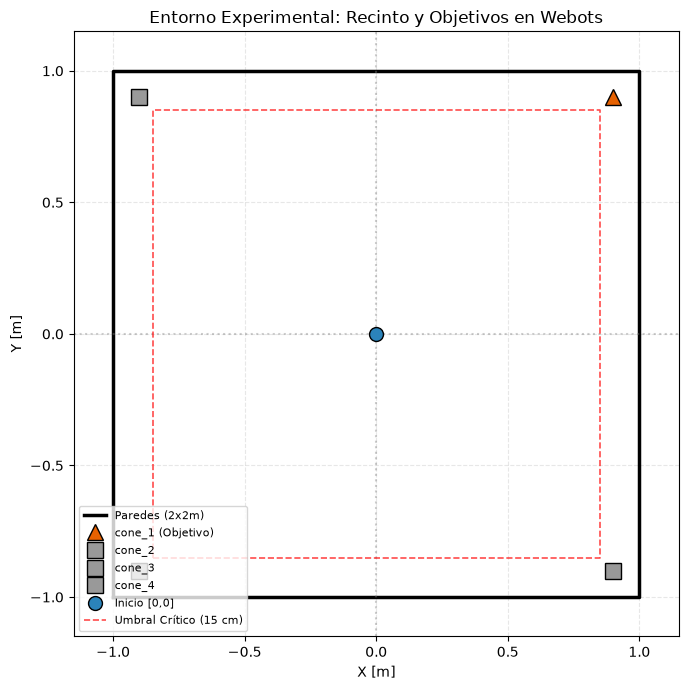

In [4]:
%matplotlib inline
fig, ax = plt.subplots(figsize=(7, 7))

# Muros perimetrales
ax.plot([-1, 1, 1, -1, -1], [-1, -1, 1, 1, -1], "k-", lw=2.5, label="Paredes (2x2m)")
ax.axhline(0, color="gray", linestyle=":", alpha=0.4)
ax.axvline(0, color="gray", linestyle=":", alpha=0.4)

# Posición de conos (coordenadas reales Webots: ±0.9m, distancia euclídea cono 1: 1.27m)
cones = {"cone_1 (Objetivo)": (0.9, 0.9), "cone_2": (-0.9, 0.9), "cone_3": (-0.9, -0.9), "cone_4": (0.9, -0.9)}
for name, (cx, cy) in cones.items():
    col = "#e66101" if "1" in name else "#999999"
    ax.plot(cx, cy, "^" if "1" in name else "s", markersize=12, color=col, markeredgecolor="black", label=name)

ax.plot(0, 0, "o", markersize=10, color="#2b83ba", markeredgecolor="black", label="Inicio [0,0]")

# Zona crítica de proximidad a paredes (15 cm)
ax.plot([-0.85, 0.85, 0.85, -0.85, -0.85], [-0.85, -0.85, 0.85, 0.85, -0.85], "r--", lw=1.2, alpha=0.7, label="Umbral Crítico (15 cm)")

ax.set_xlim(-1.15, 1.15)
ax.set_ylim(-1.15, 1.15)
ax.set_aspect("equal")
ax.set_xlabel("X [m]")
ax.set_ylabel("Y [m]")
ax.set_title("Entorno Experimental: Recinto y Objetivos en Webots")
ax.legend(loc="lower left", fontsize=8)
ax.grid(True, linestyle="--", alpha=0.3)
plt.tight_layout()
plt.show()


## 5. Tabla 4.3: Desempeño de Pilotos Sintéticos Degradados
Impacto de las perturbaciones estocásticas gaussianas (Noisy) y retardos humanos (Laggy).

In [5]:
from scripts.reproduce_results import get_table_4_3

h43, rows43 = get_table_4_3(results_dir)
df_4_3 = pd.DataFrame(rows43, columns=h43)
df_4_3

,Configuración del piloto,Tasa de éxito (%),Recompensa media,Distancia final (m),Altitud final (m),Distribución de terminaciones
0,HeuristicPilot (Control P),"100.0% [96.3, 100.0]% (100/100)",+113.69 ± 0.00,0.149 ± 0.000,0.62 ± 0.00,"100 metas, 0 caídas, 0 oob, 0 timeout"
1,NoisyPilot (sigma = 0.50),"16.0% [10.1, 24.4]% (16/100)",-32.99 ± 64.37,0.963 ± 0.573,0.38 ± 0.25,"16 metas, 33 caídas, 1 oob, 50 timeout"
2,NoisyPilot (sigma = 1.00),"4.0% [1.6, 9.8]% (4/100)",-18.68 ± 32.35,1.408 ± 0.549,0.11 ± 0.11,"4 metas, 91 caídas, 5 oob, 0 timeout"
3,LaggyPilot (p_repeat = 0.80),"100.0% [96.3, 100.0]% (100/100)",+117.05 ± 0.13,0.148 ± 0.001,0.65 ± 0.00,"100 metas, 0 caídas, 0 oob, 0 timeout"
4,StandByPilot (p_drop = 0.80),"89.0% [81.4, 93.8]% (89/100)",+92.21 ± 45.94,0.274 ± 0.443,0.61 ± 0.19,"89 metas, 9 caídas, 0 oob, 2 timeout"


## 6. Tabla 4.4 y 4.5: Efecto del Copiloto Residual (Schaff & Walter 2020)
Comparativa entre el piloto no asistido (Placebo) y el sistema asistido por el copiloto residual.

In [6]:
from scripts.reproduce_results import get_table_4_4, get_table_4_5

print("=== Tabla 4.4: Copiloto con Piloto Ruidoso (sigma = 0.50 y sigma = 1.00) ===")
h44, rows44 = get_table_4_4(results_dir)
df_4_4 = pd.DataFrame(rows44, columns=h44)
display(df_4_4)

print("\n=== Tabla 4.5: Copiloto con Piloto Lento (Laggy y StandBy) ===")
h45, rows45 = get_table_4_5(results_dir)
df_4_5 = pd.DataFrame(rows45, columns=h45)
display(df_4_5)


=== Tabla 4.4: Copiloto con Piloto Ruidoso (sigma = 0.50 y sigma = 1.00) ===


,Métrica de evaluación,Noisy solo (σ = 0.50),Con copiloto (σ = 0.50),Noisy solo (σ = 1.00),Con copiloto (σ = 1.00)
0,Tasa de éxito (%),"16.0% [10.1, 24.4]% (16/100)","14.0% [8.5, 22.1]% (14/100)","4.0% [1.6, 9.8]% (4/100)","2.0% [0.6, 7.0]% (2/100)"
1,Recompensa media acumulada,-32.99 ± 64.37,-151.93 ± 80.31,-18.68 ± 32.35,-90.19 ± 54.02
2,Longitud media global (pasos),787.84 ± 252.87 pasos,812.79 ± 218.27 pasos,142.63 ± 84.85 pasos,235.35 ± 157.31 pasos
3,Tiempo medio de vuelo,25.21 s,26.01 s,4.56 s,7.53 s
4,Distancia final a la meta (m),0.96 ± 0.57 m,1.19 ± 0.64 m,1.41 ± 0.55 m,1.44 ± 0.58 m
5,Caídas al suelo (fall),"33.0% [24.6, 42.7]% (33/100)","41.0% [31.9, 50.8]% (41/100)","91.0% [83.8, 95.2]% (91/100)","87.0% [79.0, 92.2]% (87/100)"
6,Salida de límites (out of bounds),"1.0% [0.2, 5.5]% (1/100)","4.0% [1.6, 9.8]% (4/100)","5.0% [2.1, 11.2]% (5/100)","11.0% [6.2, 18.6]% (11/100)"
7,Tiempo agotado (timeout),"50.0% [40.4, 59.6]% (50/100)","41.0% [31.9, 50.8]% (41/100)","0.0% [0.0, 3.7]% (0/100)","0.0% [0.0, 3.7]% (0/100)"
8,Supervivencia / Integridad estructural,"66.0% [56.3, 74.5]% (66/100)","55.0% [45.2, 64.4]% (55/100)","4.0% [1.6, 9.8]% (4/100)","2.0% [0.6, 7.0]% (2/100)"
9,Norma de intervención media (||a_r||),0.00,0.82 ± 0.05,0.00,0.85 ± 0.07



=== Tabla 4.5: Copiloto con Piloto Lento (Laggy y StandBy) ===


,Métrica de evaluación,Laggy solo (p_repeat = 0.80),Con copiloto (p_repeat = 0.80),StandBy solo (p_drop = 0.80),Con copiloto (p_drop = 0.80)
0,Tasa de éxito (%),"100.0% [96.3, 100.0]% (100/100)","100.0% [96.3, 100.0]% (100/100)","89.0% [81.4, 93.8]% (89/100)","70.0% [60.4, 78.1]% (70/100)"
1,Recompensa media acumulada,+117.05 ± 0.13,-41.12 ± 3.43,+92.21 ± 45.94,-79.67 ± 88.74
2,Longitud media de episodio (pasos),303.11 ± 1.47 pasos,638.04 ± 40.85 pasos,313.25 ± 151.33 pasos,528.69 ± 249.27 pasos
3,Tiempo medio de vuelo,9.70 s,20.42 s,10.02 s,16.92 s
4,Distancia final a la meta (m),0.15 ± 0.00 m,0.15 m,0.27 ± 0.44 m,0.37 ± 0.52 m
5,Caídas al suelo (fall),"0.0% [0.0, 3.7]% (0/100)","0.0% [0.0, 3.7]% (0/100)","9.0% [4.8, 16.2]% (9/100)","7.0% [3.4, 13.8]% (7/100)"
6,Salida de límites (out of bounds),"0.0% [0.0, 3.7]% (0/100)","0.0% [0.0, 3.7]% (0/100)","0.0% [0.0, 3.7]% (0/100)","7.0% [3.4, 13.8]% (7/100)"
7,Tiempo agotado (timeout),"0.0% [0.0, 3.7]% (0/100)","0.0% [0.0, 3.7]% (0/100)","2.0% [0.6, 7.0]% (2/100)","16.0% [10.1, 24.4]% (16/100)"
8,Supervivencia / Integridad estructural,"100.0% [96.3, 100.0]% (100/100)","100.0% [96.3, 100.0]% (100/100)","91.0% [83.8, 95.2]% (91/100)","86.0% [77.9, 91.5]% (86/100)"
9,Norma de intervención media (||a_r||),0.00,0.79 ± 0.01,0.00,0.71 ± 0.06


## 7. Gráficos Comparativos Resumen

Gráficos empíricos guardados en: /workspace/results_TFM/figures/

--- 1. Comparativa de Tasa de Éxito de Políticas Autónomas y Degradadas ---


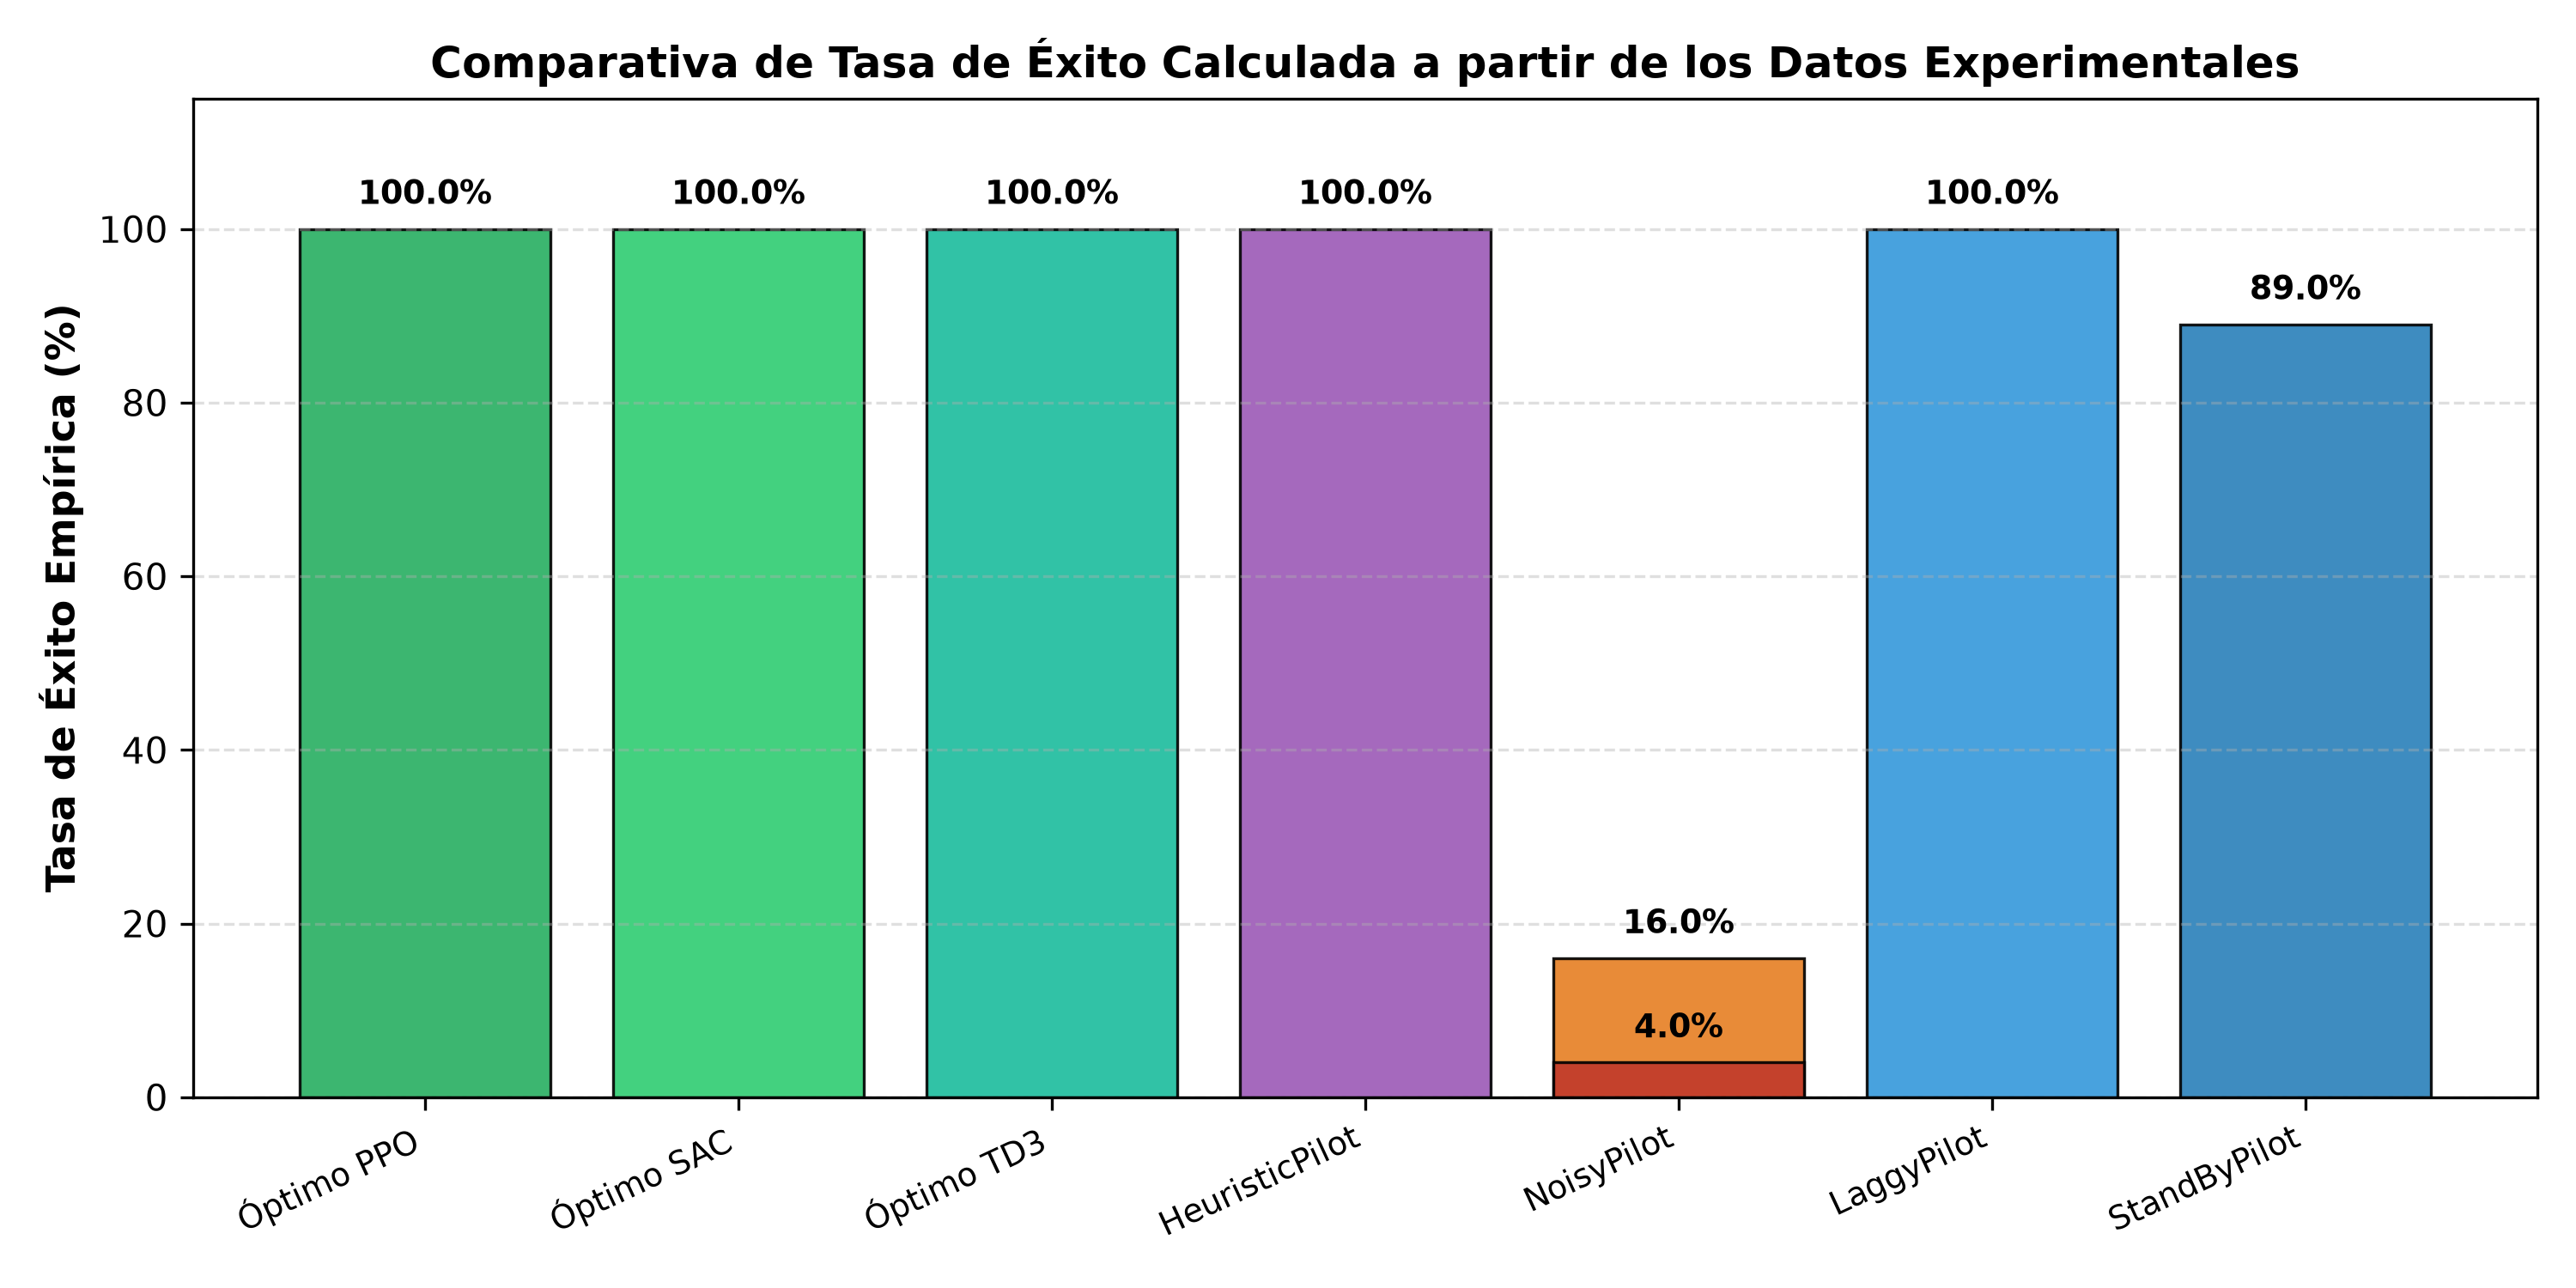


--- 2. Distribución de Terminaciones: Piloto Ruidoso (Solo vs. Copiloto) ---


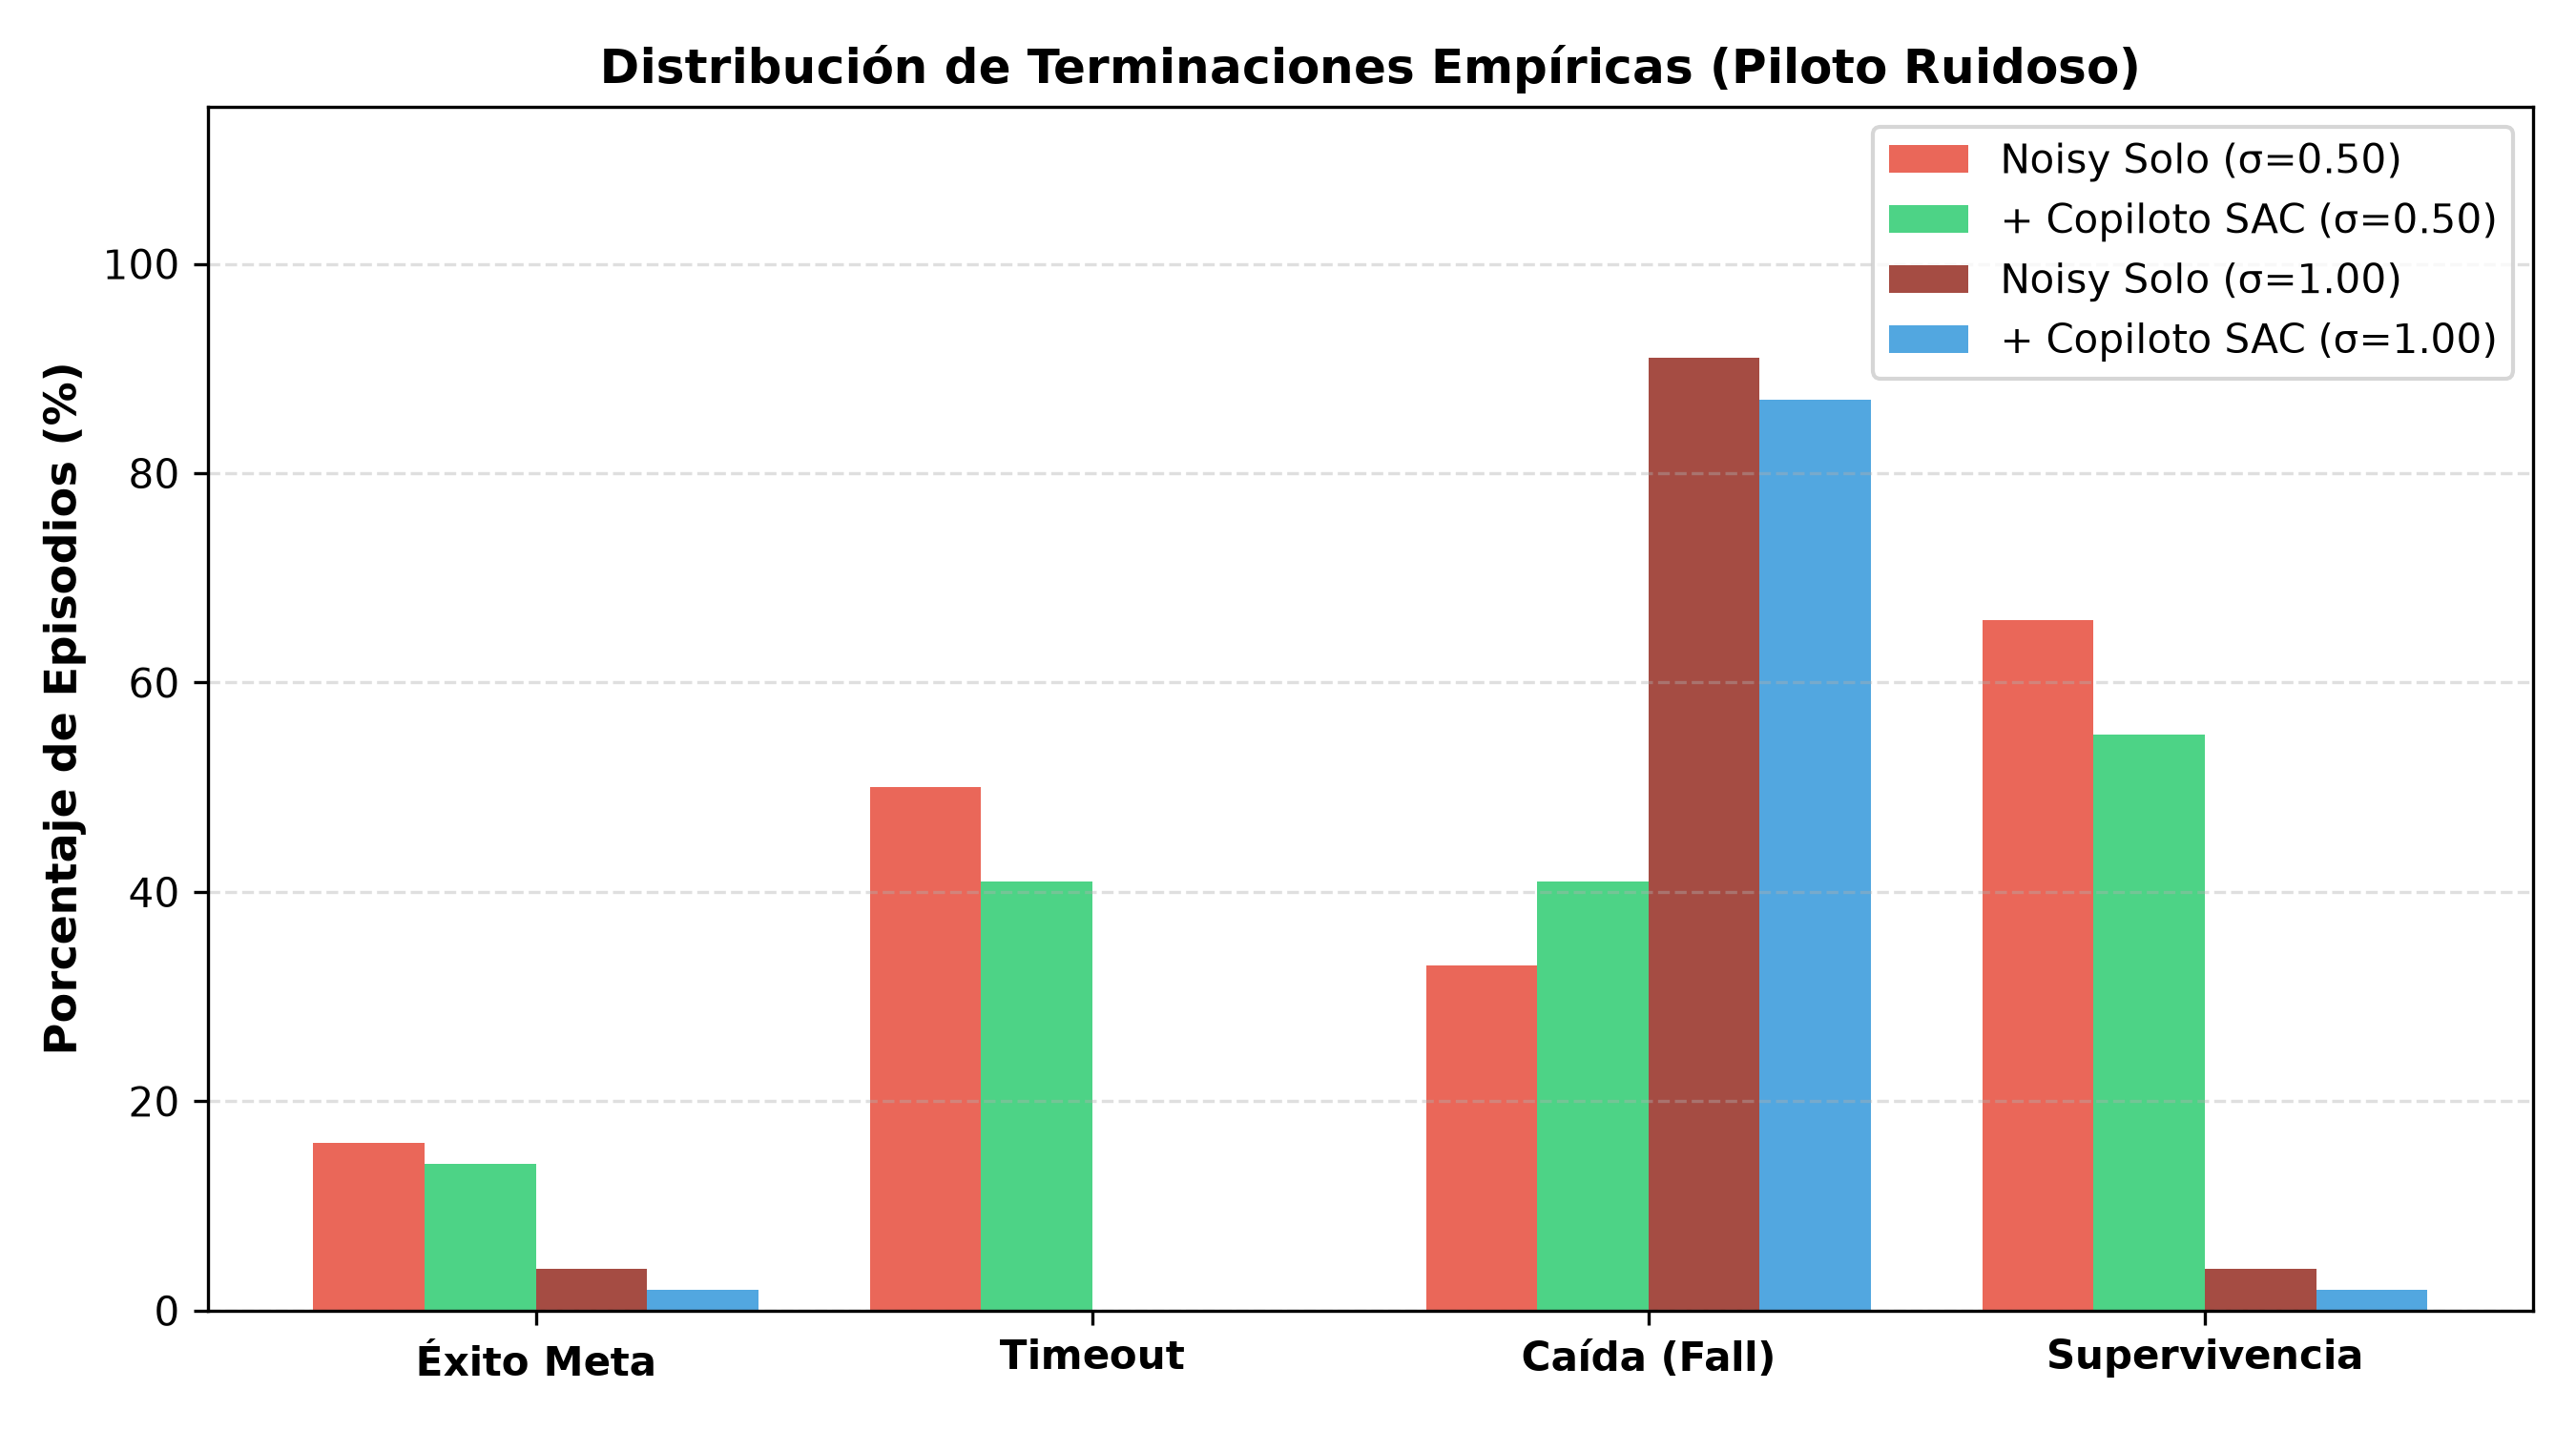


--- 3. Distribución de Terminaciones: Pilotos Laggy y StandBy (Solo vs. Copiloto) ---


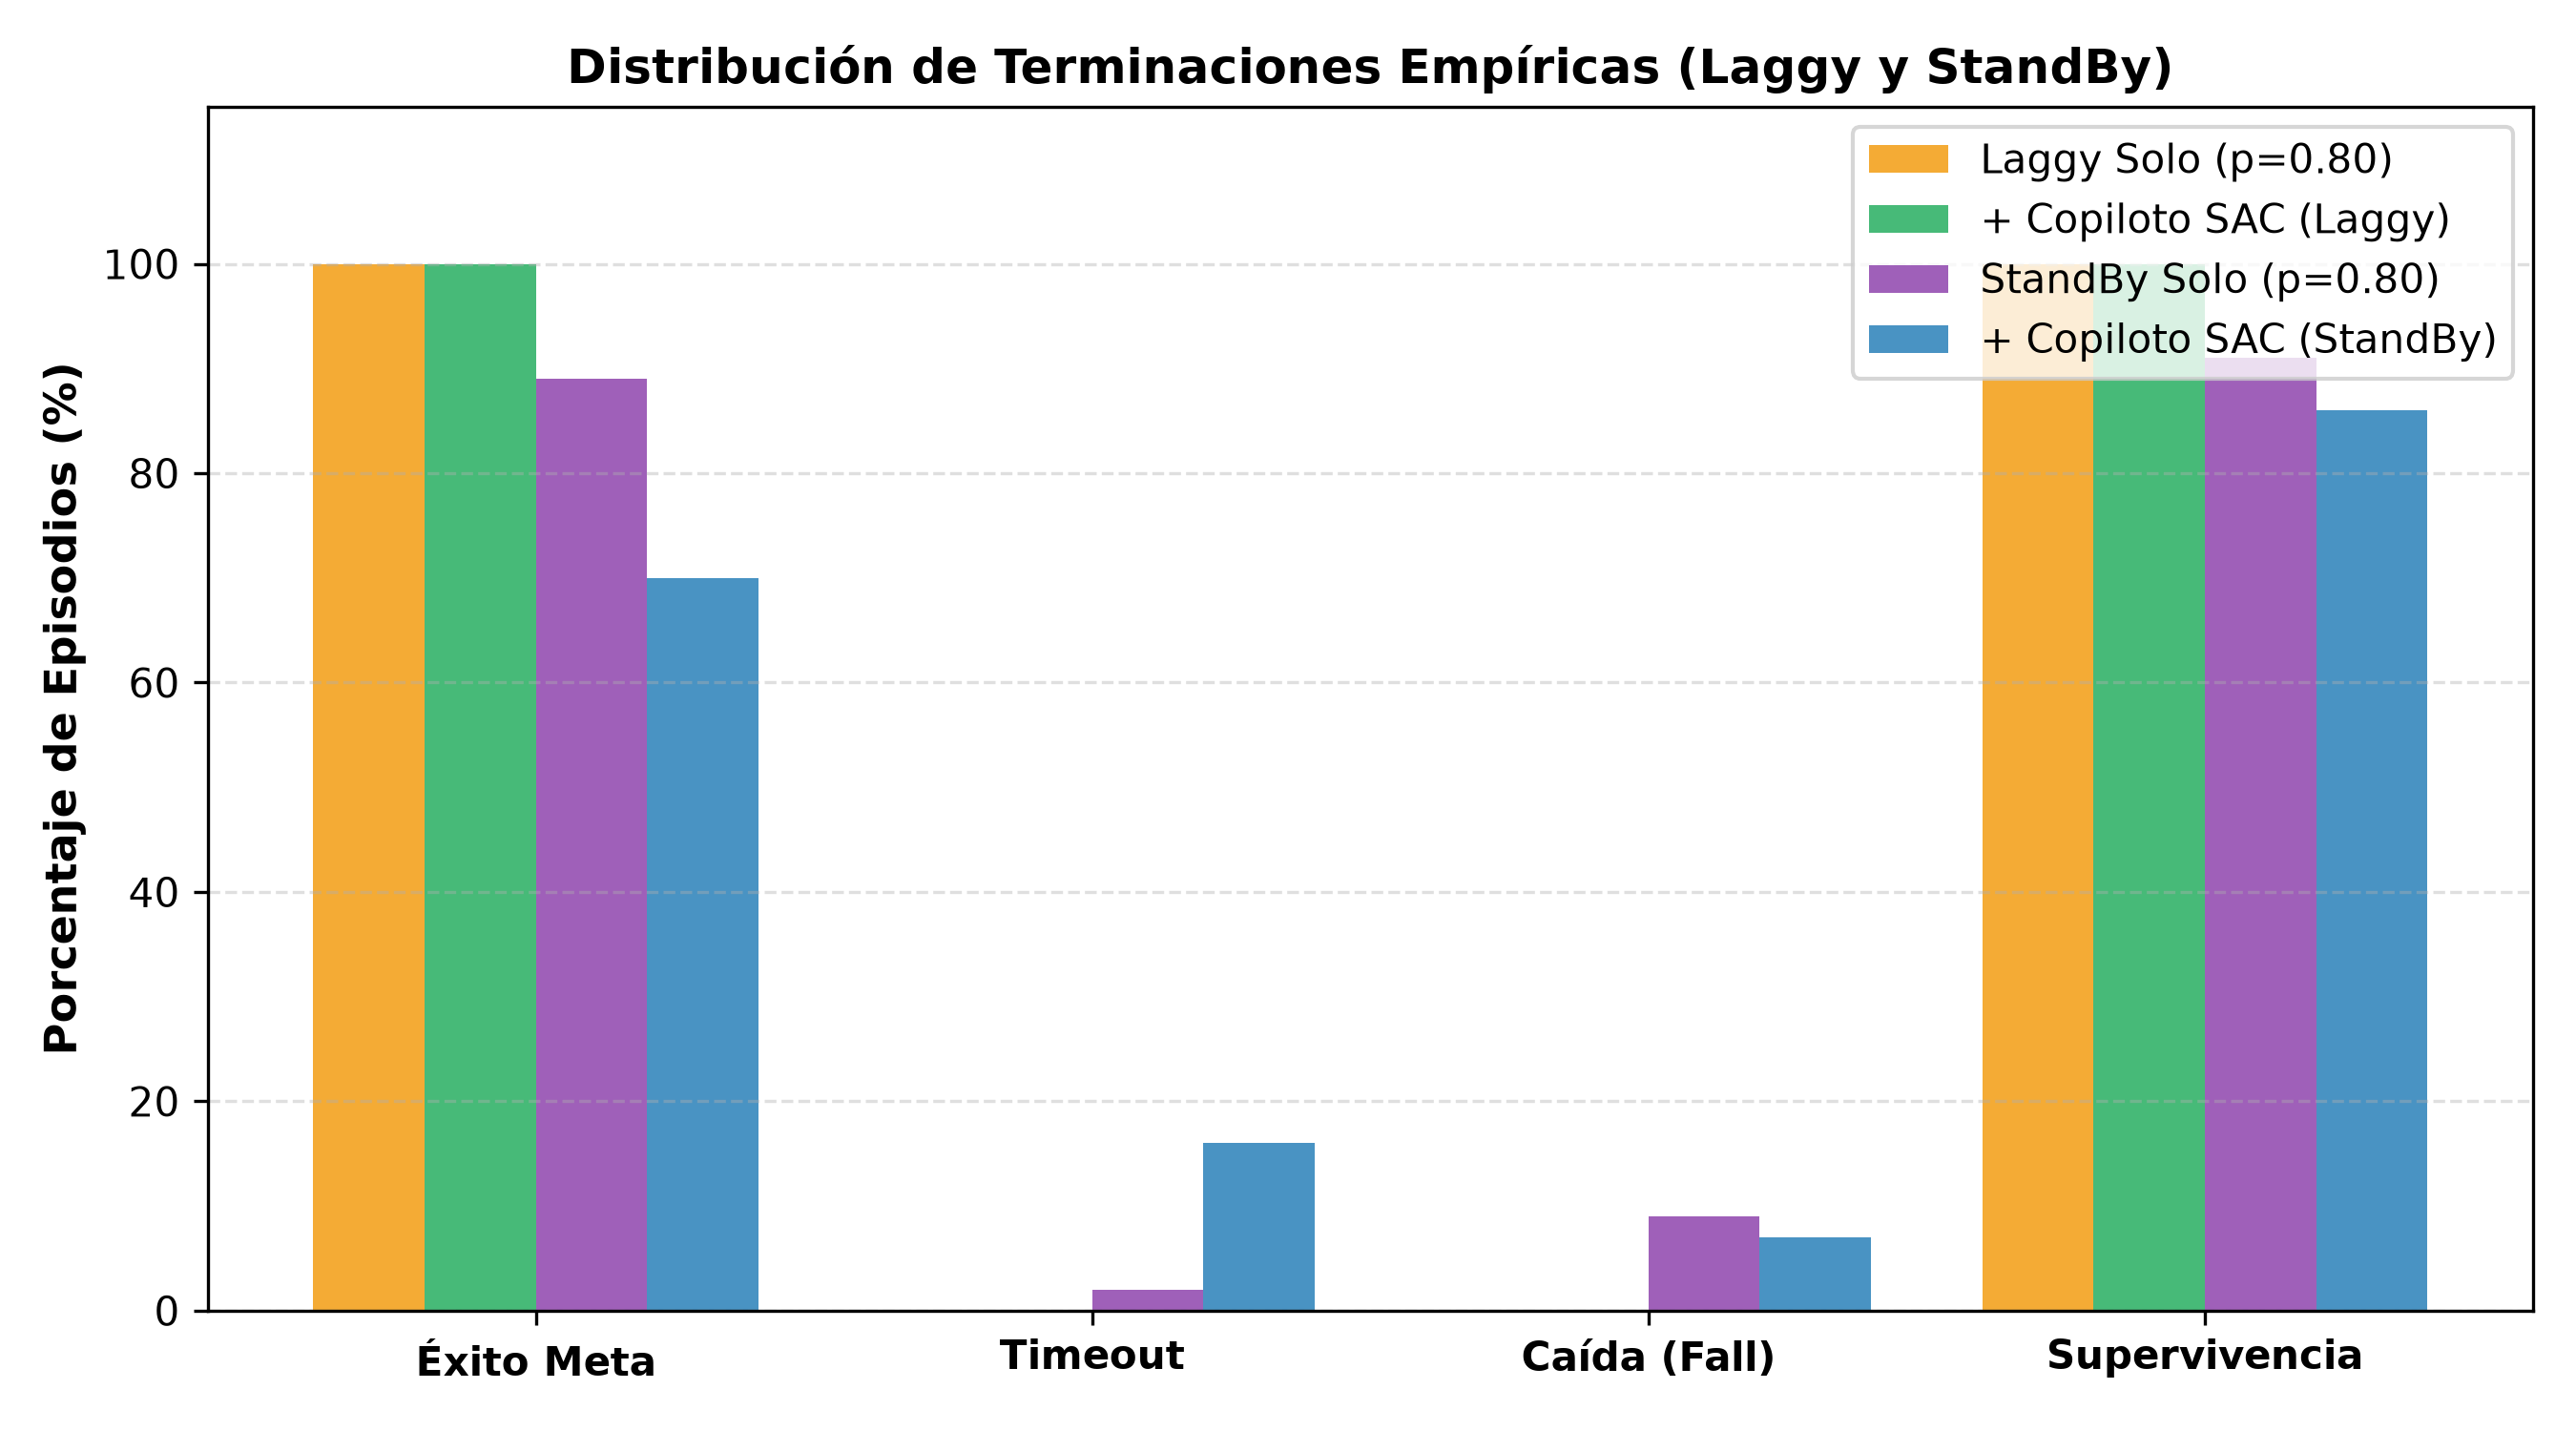


--- 4. Dashboard Consolidado de Desempeño del Copiloto (Memoria TFM Fig. 4.3) ---


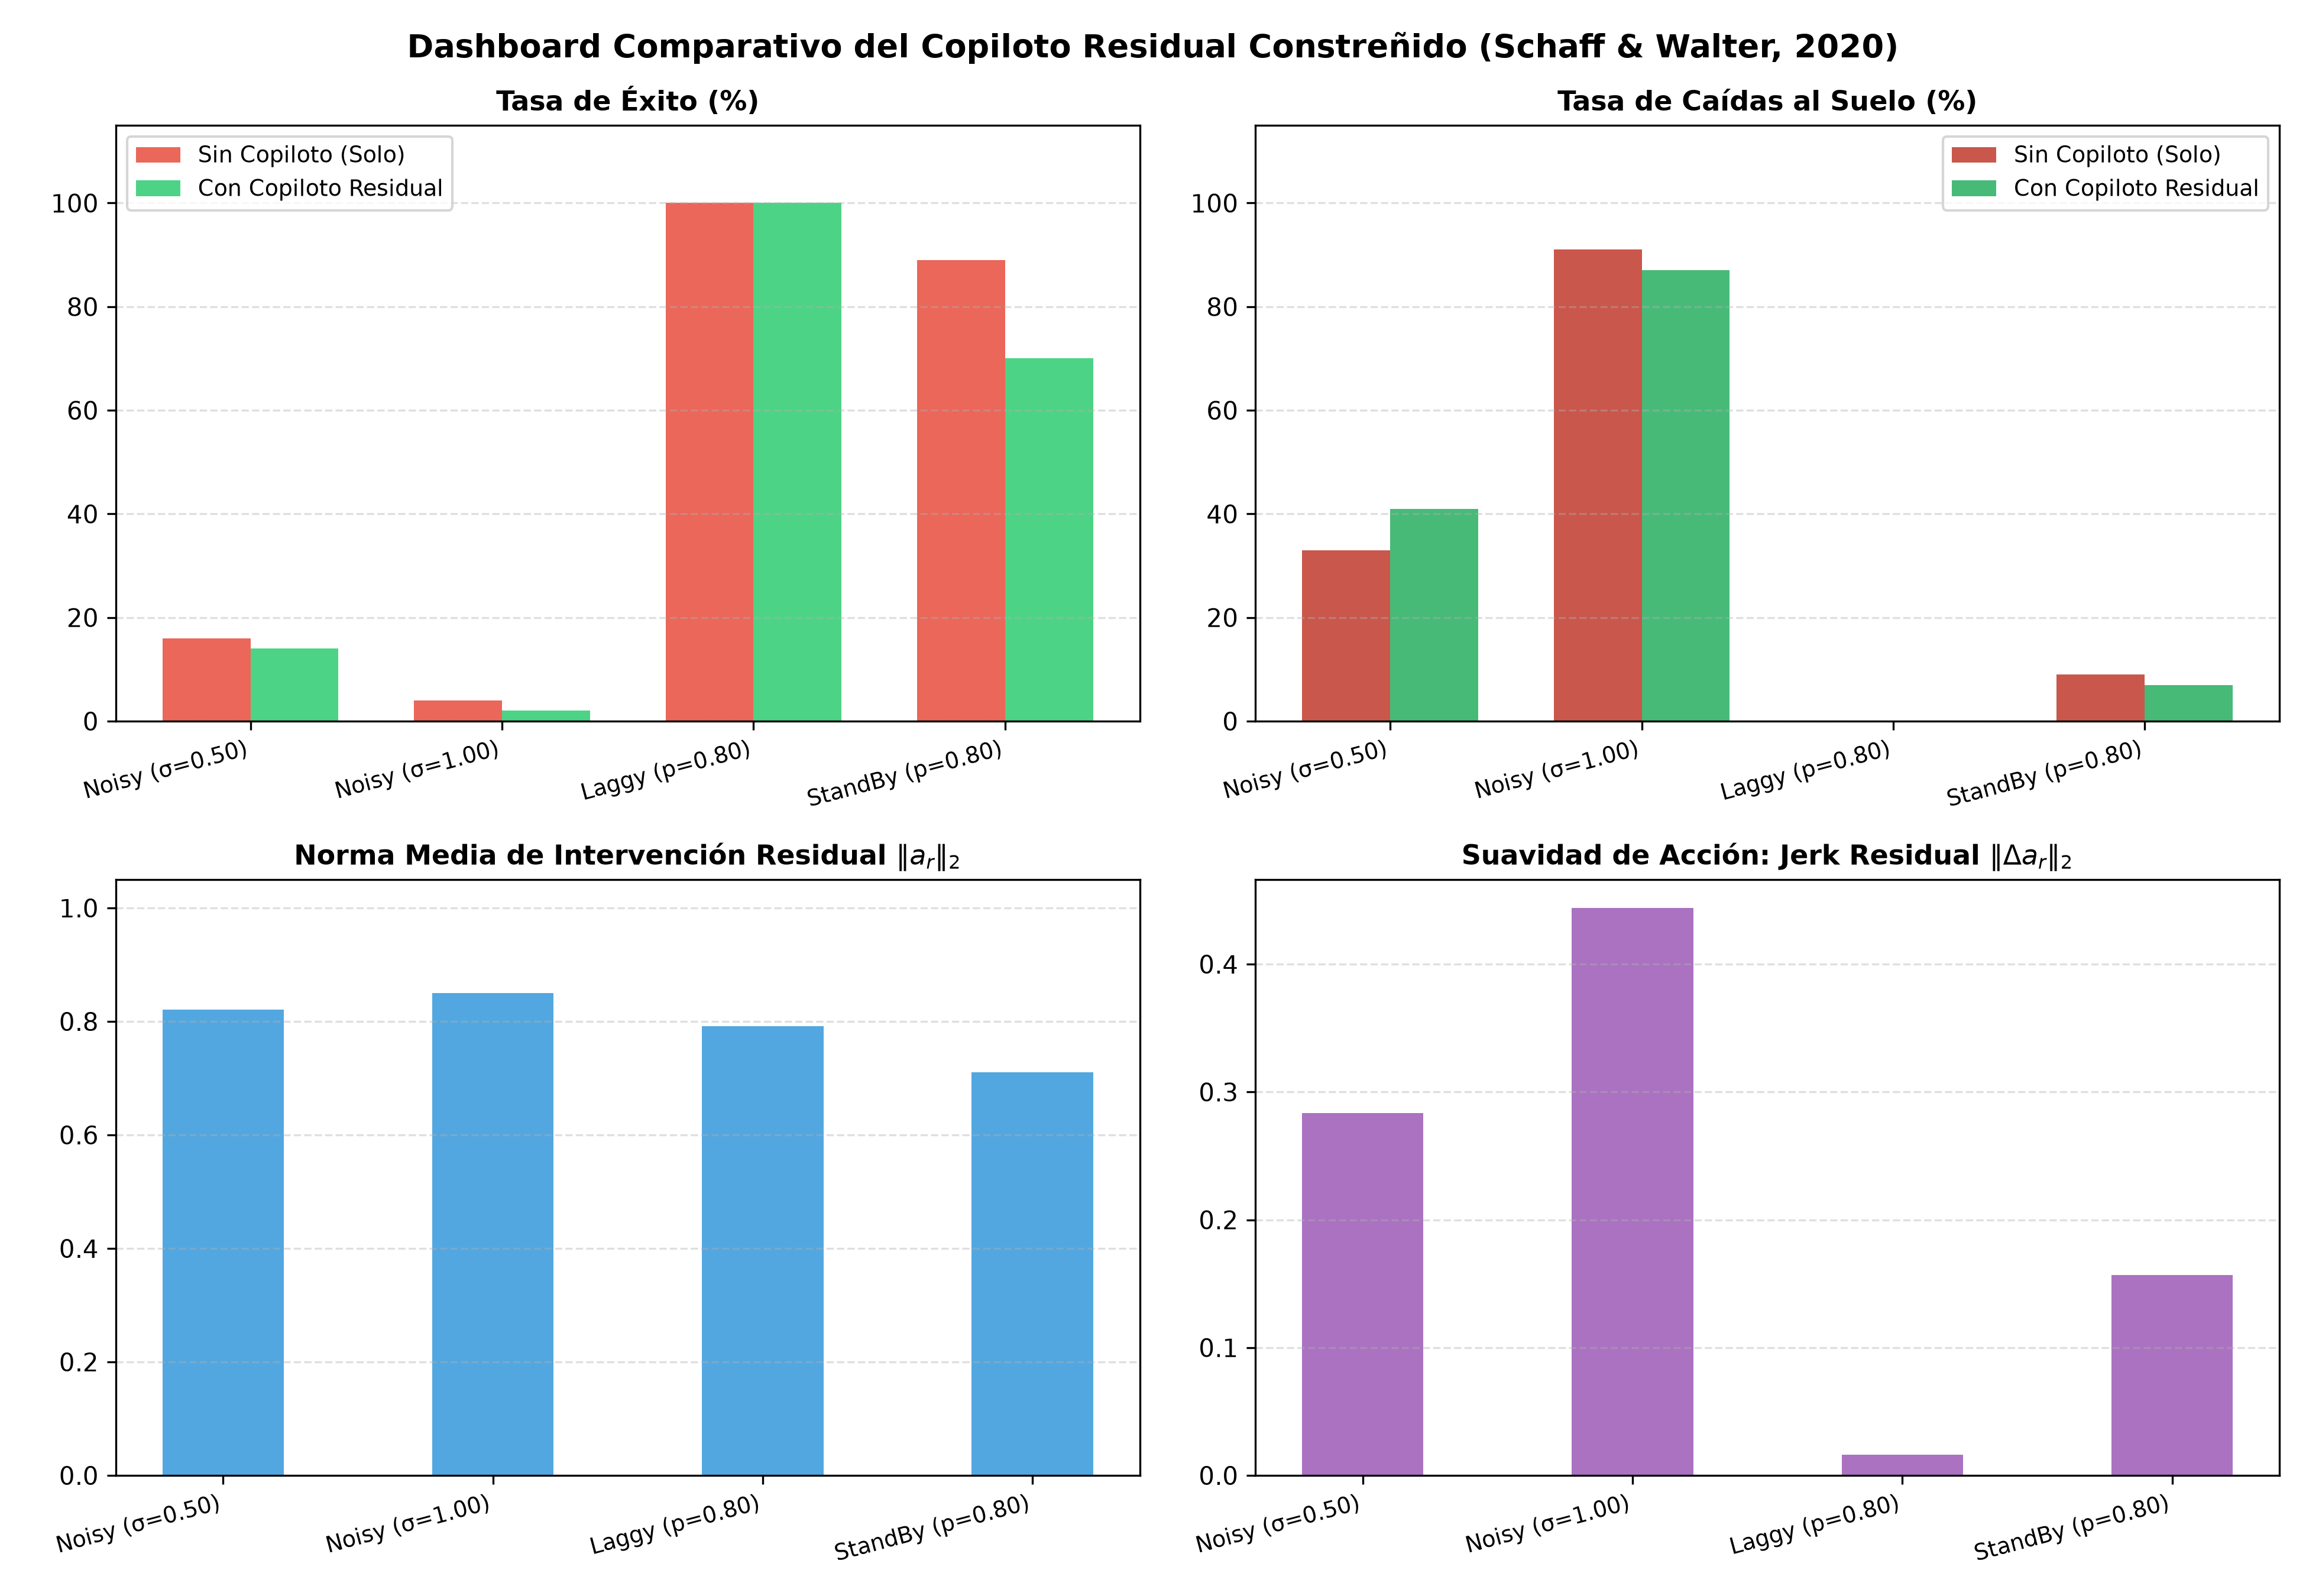

In [7]:
from scripts.reproduce_results import generate_reproduced_plots
from IPython.display import Image, display

# Generar gráficos comparativos empíricos usando los datos reales de results_TFM
generate_reproduced_plots(output_dir, results_dir=results_dir)

print("\n--- 1. Comparativa de Tasa de Éxito de Políticas Autónomas y Degradadas ---")
display(Image(filename=os.path.join(figures_dir, "comparativa_tasa_exito_pilotos.png"), width=720))

print("\n--- 2. Distribución de Terminaciones: Piloto Ruidoso (Solo vs. Copiloto) ---")
display(Image(filename=os.path.join(figures_dir, "distribucion_terminaciones_copiloto.png"), width=680))

print("\n--- 3. Distribución de Terminaciones: Pilotos Laggy y StandBy (Solo vs. Copiloto) ---")
display(Image(filename=os.path.join(figures_dir, "distribucion_terminaciones_copiloto_lento.png"), width=680))

print("\n--- 4. Dashboard Consolidado de Desempeño del Copiloto (Memoria TFM Fig. 4.3) ---")
display(Image(filename=os.path.join(figures_dir, "copilot_performance_dashboard.png"), width=820))
